In [1]:
from google.colab import files
uploaded = files.upload()

Saving Customer_Churn_Colab_Fresh_Copy_2026.zip to Customer_Churn_Colab_Fresh_Copy_2026.zip


In [3]:
import zipfile
import os

zipname = list(uploaded.keys())[0]

with zipfile.ZipFile(zipname,'r') as zip_ref:
  zip_ref.extractall('/content')

print(os.listdir('/content'))

['.config', 'Customer_Churn_Colab_Fresh_Copy_2026.zip', 'customer_churn_project', 'sample_data']


In [5]:
%cd /content/customer_churn_project
!ls

/content/customer_churn_project
app.py			       data    outputs	  REPORT_TEMPLATE.md  src
Customer_Churn_Training.ipynb  models  README.md  requirements.txt


In [6]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 90.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 103.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 116.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 113.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.9/947.9 kB 37.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [jupyter]


In [7]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [10]:
import pandas as pd

df = pd.read_csv("data/datas.csv")


print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [11]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


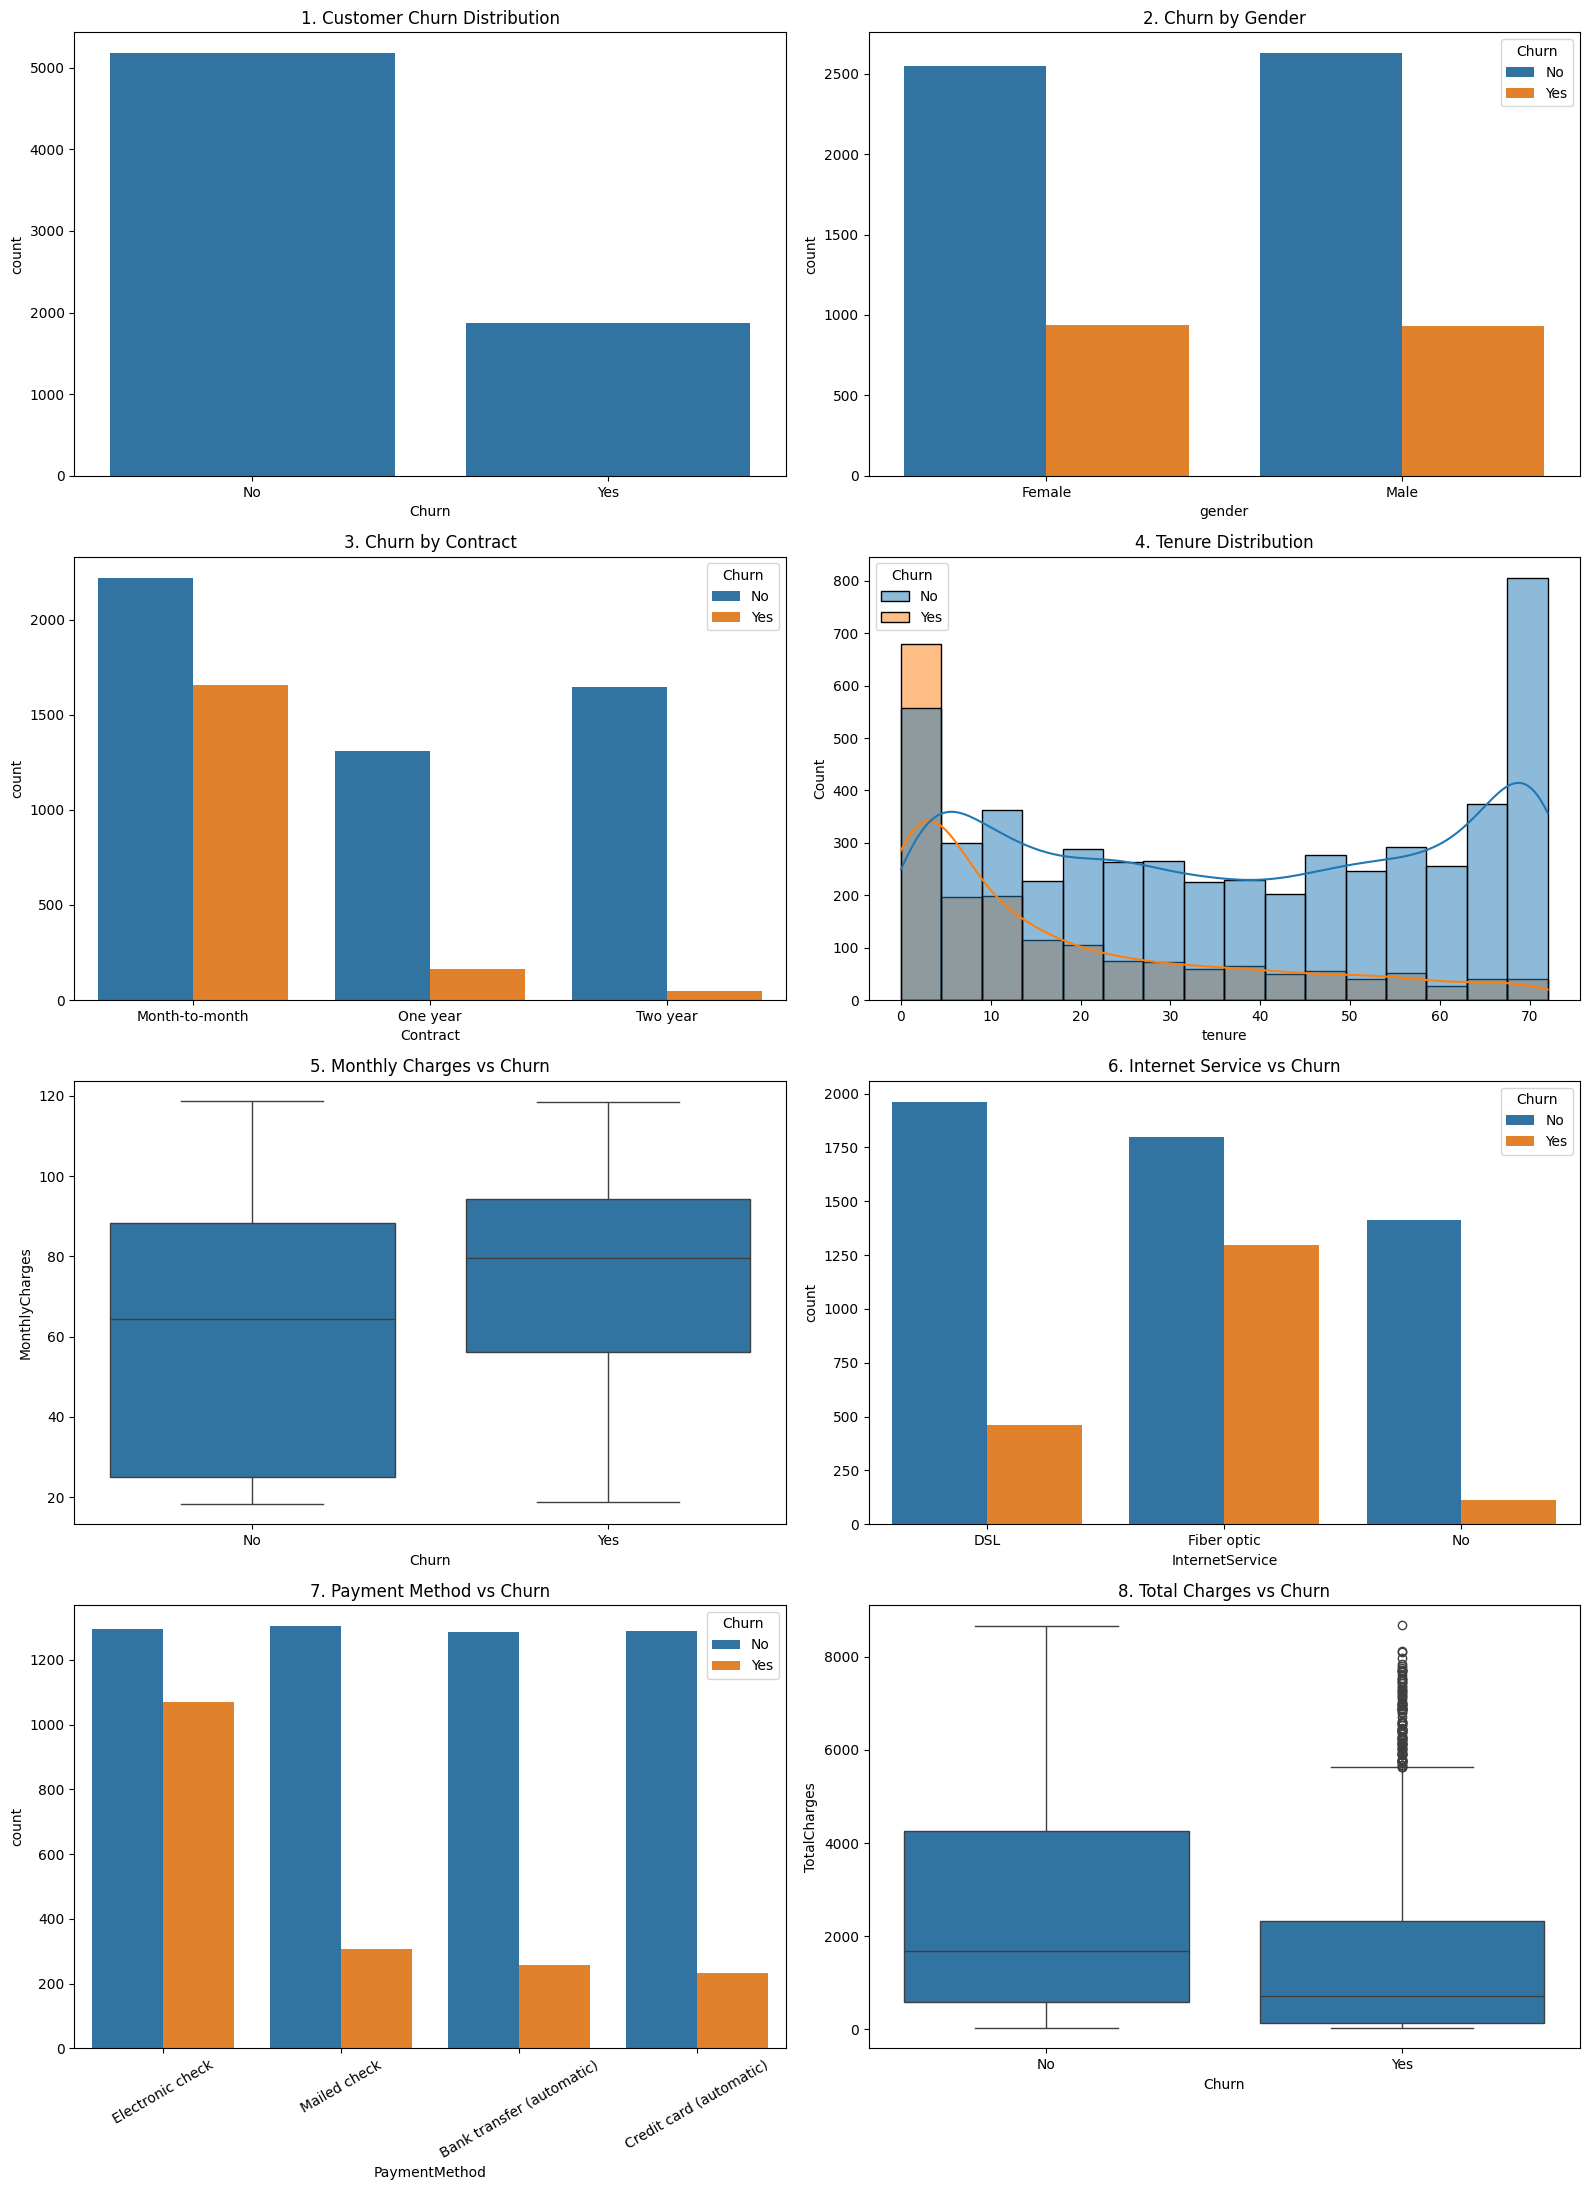

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

eda_df = df.copy()
eda_df["TotalCharges"] = pd.to_numeric(
    eda_df["TotalCharges"], errors="coerce"
)

fig, axes = plt.subplots(4, 2, figsize=(16, 22))

sns.countplot(data=eda_df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("1. Customer Churn Distribution")

sns.countplot(data=eda_df, x="gender", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("2. Churn by Gender")

sns.countplot(data=eda_df, x="Contract", hue="Churn", ax=axes[1, 0])
axes[1, 0].set_title("3. Churn by Contract")

sns.histplot(data=eda_df, x="tenure", hue="Churn", kde=True, ax=axes[1, 1])
axes[1, 1].set_title("4. Tenure Distribution")

sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges", ax=axes[2, 0])
axes[2, 0].set_title("5. Monthly Charges vs Churn")

sns.countplot(data=eda_df, x="InternetService", hue="Churn", ax=axes[2, 1])
axes[2, 1].set_title("6. Internet Service vs Churn")

sns.countplot(data=eda_df, x="PaymentMethod", hue="Churn", ax=axes[3, 0])
axes[3, 0].tick_params(axis="x", rotation=30)
axes[3, 0].set_title("7. Payment Method vs Churn")

sns.boxplot(data=eda_df, x="Churn", y="TotalCharges", ax=axes[3, 1])
axes[3, 1].set_title("8. Total Charges vs Churn")

plt.tight_layout()
plt.show()


In [13]:
import os

os.makedirs("outputs/eda", exist_ok=True)

fig.savefig(
    "outputs/eda/churn_eda.png",
    dpi=300,
    bbox_inches="tight"
)

print("8 EDA graphs saved successfully!")


8 EDA graphs saved successfully!


In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Original dataset ki copy
data = df.copy()

# Numeric conversion
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Target variable
y = data["Churn"].map({"No": 0, "Yes": 1})

# Customer ID aur target remove
X = data.drop(columns=["customerID", "Churn"])

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["int64", "float64"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training records: 5634
Testing records: 1409
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),
    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1"],
        n_jobs=-1
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

    print(name, "training completed!")

results_df = pd.DataFrame(results)
display(results_df)

Logistic Regression training completed!
Random Forest training completed!
SVM training completed!
XGBoost training completed!


,Model,CV Accuracy,CV F1
0,Logistic Regression,0.748138,0.627927
1,Random Forest,0.785235,0.537990
2,SVM,0.750268,0.624037
3,XGBoost,0.784171,0.554369


In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Logistic Regression tuning
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

lr_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Logistic Regression Best Parameters:")
print(lr_grid.best_params_)
print("Best CV F1:", lr_grid.best_score_)


# Random Forest tuning
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 3]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("\nRandom Forest Best Parameters:")
print(rf_grid.best_params_)
print("Best CV F1:", rf_grid.best_score_)

Logistic Regression Best Parameters:
{'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}
Best CV F1: 0.6294582040225383

Random Forest Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
Best CV F1: 0.6305658922337039


In [17]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Best CV F1": [
        lr_grid.best_score_,
        rf_grid.best_score_
    ],
    "Best Parameters": [
        str(lr_grid.best_params_),
        str(rf_grid.best_params_)
    ]
})

display(comparison)

,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.629458,"{'classifier__C': 0.1, 'classifier__solver': '..."
1,Random Forest,0.630566,"{'classifier__max_depth': 10, 'classifier__min..."


In [18]:
import os
import joblib

best_model = rf_grid.best_estimator_
best_model_name = "Random Forest"

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/best_pipeline.joblib"
)

print("Selected Model:", best_model_name)
print("Model saved successfully!")

Selected Model: Random Forest
Model saved successfully!


In [19]:
from sklearn.metrics import accuracy_score, f1_score

train_predictions = best_model.predict(X_train)

train_accuracy = accuracy_score(y_train, train_predictions)
train_f1 = f1_score(y_train, train_predictions)

print("Training Accuracy:", round(train_accuracy, 4))
print("Training F1:", round(train_f1, 4))
print("Cross-validation F1:", round(rf_grid.best_score_, 4))
print("F1 Gap:", round(train_f1 - rf_grid.best_score_, 4))

Training Accuracy: 0.8397
Training F1: 0.7438
Cross-validation F1: 0.6306
F1 Gap: 0.1133


FINAL MODEL EVALUATION
----------------------
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.54      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC Score: 0.839


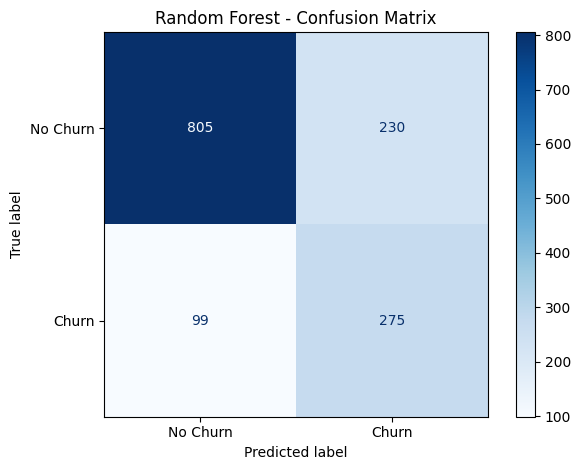

In [20]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("FINAL MODEL EVALUATION")
print("----------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("ROC-AUC Score:",
      round(roc_auc_score(y_test, y_prob), 4))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()

os.makedirs("outputs", exist_ok=True)
plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,Feature,Importance
14,Contract,0.134278
7,InternetService,0.080710
4,tenure,0.054527
16,PaymentMethod,0.052086
8,OnlineSecurity,0.042772


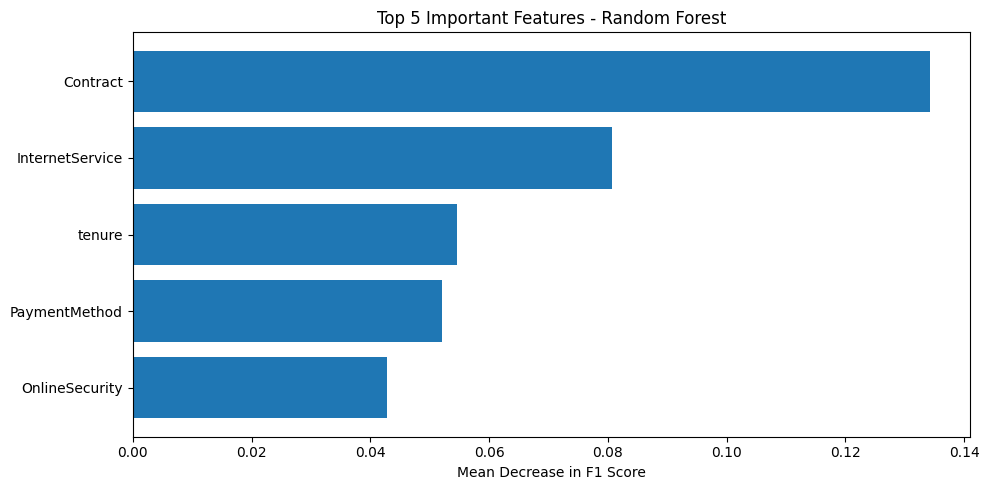

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Validation data par feature importance
# Test set ko model selection ke liye dobara use nahi karenge
X_imp, _, y_imp, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.25,
    random_state=42,
    stratify=y_train
)

importance = permutation_importance(
    best_model,
    X_imp,
    y_imp,
    n_repeats=5,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_imp.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

top5 = feature_importance.head(5)

display(top5)

plt.figure(figsize=(10, 5))
plt.barh(
    top5["Feature"][::-1],
    top5["Importance"][::-1]
)

plt.xlabel("Mean Decrease in F1 Score")
plt.title("Top 5 Important Features - Random Forest")
plt.tight_layout()

plt.savefig(
    "outputs/top5_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
import os
import joblib

model_path = "models/best_pipeline.joblib"

print("Model exists:", os.path.exists(model_path))

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]

probability = loaded_model.predict_proba(sample)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn Probability:", round(probability * 100, 2), "%")

Model exists: True
Model loaded successfully!
Prediction: No Churn
Churn Probability: 2.79 %


In [23]:
import os

print("Current folder:", os.getcwd())
print("Dashboard exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("models/best_pipeline.joblib"))

if os.path.exists("app.py"):
    with open("app.py", "r", encoding="utf-8") as f:
        print(f.read())

Current folder: /content/customer_churn_project
Dashboard exists: True
Model exists: True
from pathlib import Path
import joblib, pandas as pd, streamlit as st
ROOT=Path(__file__).resolve().parent
st.set_page_config(page_title='Customer Churn Predictor',layout='wide')
st.title('Customer Churn Prediction Dashboard')
st.caption('IBM Telco Customer Churn | ML-based decision support')
model_path=ROOT/'models'/'best_pipeline.joblib'
if not model_path.exists():
    st.warning('Train the model first: python -m src.train --data data/Telco-Customer-Churn.csv')
    st.stop()
model=joblib.load(model_path); schema=joblib.load(ROOT/'models'/'schema.joblib')
with st.form('prediction'):
    cols=st.columns(3); values={}
    for i,c in enumerate(schema['columns']):
        with cols[i%3]:
            if c in schema['categorical_values']:
                values[c]=st.selectbox(c,schema['categorical_values'][c])
            else:
                values[c]=st.number_input(c,value=schema['numeric_defaults

In [24]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.66.1


In [25]:
!streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [26]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://localhost:8501/_stcore/health")
    print("Dashboard status:", response.status_code)
except Exception as e:
    print("Dashboard error:", e)

!tail -20 /content/streamlit.log

Dashboard status: 200


2026-10-29 04:26:32.682 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.117.186.80:8501



In [27]:
import os
import subprocess
import time

# Start Streamlit server
log = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process:", process.poll())
print("Server log:")
print(open("/content/streamlit.log").read()[-2000:])

Streamlit process: None
Server log:


2026-10-29 04:28:56.812 Port 8501 is not available



In [28]:
import subprocess
import time

log = open("/content/streamlit_8502.log", "w")

process2 = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8502",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Process running:", process2.poll() is None)
print(open("/content/streamlit_8502.log").read()[-2000:])

Process running: True
2026-10-29 04:29:45.686 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://136.117.186.80:8502




In [29]:
from google.colab import output
from IPython.display import display, HTML

url = output.eval_js(
    "google.colab.kernel.proxyPort(8502)"
)

print("Your Dashboard URL:")
print(url)

display(HTML(
    f'<a href="{url}" target="_blank">'
    'CLICK HERE TO OPEN DASHBOARD</a>'
))

Your Dashboard URL:
https://8502-m-s-usw1b1-1ifwkb5reghv6-b.us-west1.prod.r.colab.dev


In [30]:
import requests

try:
    r = requests.get(
        "http://127.0.0.1:8502/_stcore/health",
        timeout=10
    )
    print("Server Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", e)

Server Status: 200
Response: ok


In [31]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8502,
    height=700
)

<IPython.core.display.Javascript object>

In [32]:
import os
import requests

print("Current directory:", os.getcwd())
print("App exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("models/best_pipeline.joblib"))

for port in [8501, 8502, 8503]:
    try:
        r = requests.get(
            f"http://127.0.0.1:{port}/_stcore/health",
            timeout=3
        )
        print(f"Port {port}: {r.status_code}")
    except Exception:
        print(f"Port {port}: Not running")

for filename in [
    "/content/streamlit.log",
    "/content/streamlit_8502.log",
    "/content/streamlit_8503.log"
]:
    if os.path.exists(filename):
        print("\nLOG:", filename)
        print(open(filename).read()[-2000:])

Current directory: /content/customer_churn_project
App exists: True
Model exists: True
Port 8501: 200
Port 8502: 200
Port 8503: Not running

LOG: /content/streamlit.log


2026-10-29 04:28:56.812 Port 8501 is not available


LOG: /content/streamlit_8502.log
al:8007
2026-10-29 04:35:14.240 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8502-m-s-usw1b1-1ifwkb5reghv6-b.us-west1.prod.r.colab.dev, host=m-s-usw1b1-1ifwkb5reghv6.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-10-29 04:35:19.216 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8502-m-s-usw1b1-1ifwkb5reghv6-b.us-west1.prod.r.colab.dev, host=m-s-usw1b1-1ifwkb5reghv6.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-10-29 04:35:23.665 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8502-m-s-usw1b1-1ifwkb5reghv6-b.us-west1.prod.r.colab.dev, host=m-s-usw1b1-1ifwkb5reghv6.us-west1-b.c.codatalab-user-runtimes.in

In [33]:
with open("app.py", "r", encoding="utf-8") as f:
    print(f.read())

from pathlib import Path
import joblib, pandas as pd, streamlit as st
ROOT=Path(__file__).resolve().parent
st.set_page_config(page_title='Customer Churn Predictor',layout='wide')
st.title('Customer Churn Prediction Dashboard')
st.caption('IBM Telco Customer Churn | ML-based decision support')
model_path=ROOT/'models'/'best_pipeline.joblib'
if not model_path.exists():
    st.warning('Train the model first: python -m src.train --data data/Telco-Customer-Churn.csv')
    st.stop()
model=joblib.load(model_path); schema=joblib.load(ROOT/'models'/'schema.joblib')
with st.form('prediction'):
    cols=st.columns(3); values={}
    for i,c in enumerate(schema['columns']):
        with cols[i%3]:
            if c in schema['categorical_values']:
                values[c]=st.selectbox(c,schema['categorical_values'][c])
            else:
                values[c]=st.number_input(c,value=schema['numeric_defaults'][c])
    submitted=st.form_submit_button('Predict churn risk',type='primary')
if submitt

In [34]:
import os
import joblib

# Categorical values from training data
categorical_values = {}

for col in categorical_features:
    categorical_values[col] = sorted(
        X_train[col].dropna().astype(str).unique().tolist()
    )

# Numeric default values
numeric_defaults = {}

for col in numeric_features:
    numeric_defaults[col] = float(
        X_train[col].median()
    )

# Dashboard schema
schema = {
    "columns": X_train.columns.tolist(),
    "categorical_values": categorical_values,
    "numeric_defaults": numeric_defaults
}

os.makedirs("models", exist_ok=True)

joblib.dump(schema, "models/schema.joblib")

print("Schema created successfully!")
print("Columns:", len(schema["columns"]))
print("Schema exists:", os.path.exists("models/schema.joblib"))

Schema created successfully!
Columns: 19
Schema exists: True


In [35]:
import os

print(
    "Model:",
    os.path.exists("models/best_pipeline.joblib")
)

print(
    "Schema:",
    os.path.exists("models/schema.joblib")
)

Model: True
Schema: True


In [36]:
import pandas as pd
import joblib

model = joblib.load("models/best_pipeline.joblib")
schema = joblib.load("models/schema.joblib")

values = {}

for col in schema["columns"]:
    if col in schema["categorical_values"]:
        values[col] = schema["categorical_values"][col][0]
    else:
        values[col] = schema["numeric_defaults"][col]

customer = pd.DataFrame([values])

prediction = model.predict(customer)[0]
probability = model.predict_proba(customer)[0, 1]

print("Dashboard Model Test Successful!")
print("Prediction:", prediction)
print("Churn Probability:", round(probability * 100, 2), "%")

Dashboard Model Test Successful!
Prediction: 0
Churn Probability: 32.69 %


In [37]:
import requests

for port in [8502, 8503]:
    try:
        response = requests.get(
            f"http://127.0.0.1:{port}/_stcore/health",
            timeout=3
        )
        print(f"Port {port}: {response.status_code}")
    except Exception:
        print(f"Port {port}: Not running")

Port 8502: 200
Port 8503: Not running


In [38]:
from google.colab import output

output.serve_kernel_port_as_window(8502)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [39]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /tmp/cloudflared

!chmod +x /tmp/cloudflared

In [40]:
import subprocess
import time
import re

tunnel_log = open("/content/tunnel.log", "w")

tunnel = subprocess.Popen(
    [
        "/tmp/cloudflared",
        "tunnel",
        "--url",
        "http://127.0.0.1:8502",
        "--no-autoupdate"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT
)

time.sleep(12)

logs = open("/content/tunnel.log").read()

urls = re.findall(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
    logs
)

if urls:
    print("YOUR DASHBOARD LINK:")
    print(urls[0])
else:
    print("Tunnel link not found. Logs:")
    print(logs[-3000:])

YOUR DASHBOARD LINK:
https://firms-here-mark-teacher.trycloudflare.com


In [41]:
import os
import shutil
from google.colab import files

print("Current folder:", os.getcwd())

# Project ki ZIP banao
shutil.make_archive(
    "/content/customer_churn_final",
    "zip",
    root_dir="/content",
    base_dir="customer_churn_project"
)

print("ZIP created successfully!")

files.download("/content/customer_churn_final.zip")

Current folder: /content/customer_churn_project
ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>